# The stellar graveyard: what colliding black holes and neutron stars tell us

**Project 18 question:** How heavy are the black holes and neutron stars that collide across the universe, and are there masses nature seems to avoid?

**What are we looking at?** When a very massive star dies, it can leave behind a **neutron star** (a city-sized ball of packed neutrons, up to about 2-3 times the Sun's mass) or a **black hole** (heavier still; not even light escapes). Sometimes two of these dead stars orbit each other, spiral together and collide. The collision shakes space itself, sending out ripples called **gravitational waves**. The LIGO (USA), Virgo (Italy) and KAGRA (Japan) detectors pick up those ripples. From the shape of the signal, scientists work out how heavy each object was and roughly how far away the collision happened.

**The data:** the Gravitational-Wave Transient Catalog (GWTC-1 up to GWTC-5.0), one row per confident detection, from the Gravitational Wave Open Science Center (https://gwosc.org). Full citation at the end.

**Words used below**
- **Solar mass (M☉):** the mass of our Sun. "30 solar masses" = 30 times heavier than the Sun.
- **Megaparsec (Mpc):** a distance unit astronomers use for galaxies. 1 Mpc ≈ 3.26 million light-years.
- **Log scale:** an axis where each step multiplies instead of adds (1, 10, 100...). It lets small and huge values fit on one chart.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CATALOG_URL = 'https://gwosc.org/eventapi/csv/GWTC/'   # every confident detection, GWTC-1 to GWTC-5.0
DATA_FILE = Path('../data/gwtc_events.csv')            # saved copy, so we only download once
PLOTS = Path('../plots')                               # every figure is also saved here as a PNG
PLOTS.mkdir(exist_ok=True)

# One colour and marker shape per type of collision, plus grey for shaded regions and dark grey for labels
TYPE_STYLE = {
    'Two black holes':           ('#2a78d6', 'o'),   # blue circles
    'Black hole + neutron star': ('#eb6834', 's'),   # orange squares
    'Two neutron stars':         ('#1baf7a', 'D'),   # green diamonds
}
BLUE, GREY, INK = '#2a78d6', '#dddcd8', '#52514e'

## Load the catalogue

The first time, this downloads the catalogue from GWOSC (about 100 kB) and saves a copy in `data/`. After that it reads the saved copy.

In [2]:
if DATA_FILE.exists():
    events = pd.read_csv(DATA_FILE)
    print('Read the saved copy in', DATA_FILE)
else:
    events = pd.read_csv(CATALOG_URL)
    DATA_FILE.parent.mkdir(exist_ok=True)
    events.to_csv(DATA_FILE, index=False)
    print('Downloaded from GWOSC and saved to', DATA_FILE)

print(len(events), 'collisions in the catalogue')
events[['commonName', 'mass_1_source', 'mass_2_source', 'final_mass_source', 'luminosity_distance']].head()

Read the saved copy in ../data/gwtc_events.csv
391 collisions in the catalogue


,commonName,mass_1_source,mass_2_source,final_mass_source,luminosity_distance
0,GW150914,34.6,30.0,61.5,470.0
1,GW151012,24.8,13.6,37.1,1000.0
2,GW151226,14.2,7.5,20.7,460.0
3,GW170104,28.7,20.8,47.5,1110.0
4,GW170608,10.6,7.8,17.7,340.0


Each row is one collision. The columns we use:
- `commonName`: the event's name, which is also its detection date (GW170817 = 17 August 2017).
- `mass_1_source`, `mass_2_source`: the masses of the heavier and the lighter object, in solar masses.
- `final_mass_source`: the mass of the single object left after they merge.
- `luminosity_distance`: how far away the collision was, in megaparsecs.

The `_lower` and `_upper` columns give each value's uncertainty. Every mass and distance is a **best estimate**, not an exact number.

## Add a date and a type to each collision

We sort collisions into three types using the rough dividing line of **3 solar masses**: lighter objects are probably neutron stars, heavier ones black holes. This is our own simple label, not the official classification, and objects close to the line could be either.

In [3]:
# Each event is named after the day it was detected: GW170817 = 17 August 2017
events['date'] = pd.to_datetime(events['commonName'].str[2:8], format='%y%m%d')

# mass_1 is always the heavier partner, so if mass_1 is under 3 solar masses, both are.
NS_LIMIT = 3  # solar masses

def collision_type(row):
    if pd.isna(row['mass_1_source']) or pd.isna(row['mass_2_source']):
        return 'No masses published yet'
    if row['mass_1_source'] < NS_LIMIT:
        return 'Two neutron stars'
    if row['mass_2_source'] < NS_LIMIT:
        return 'Black hole + neutron star'
    return 'Two black holes'

events['type'] = events.apply(collision_type, axis=1)
events['type'].value_counts()

type
Two black holes              273
No masses published yet      109
Black hole + neutron star      7
Two neutron stars              2
Name: count, dtype: int64

## 1. How heavy are the dead stars?

Every collision involves two objects, so we put **both partners** from every collision into one histogram. Each bar counts how many objects have that mass.

The grey bands mark two mass ranges where theory predicts **few or no objects**:
- **Lower mass gap (~3-5 M☉):** heavier than the heaviest neutron stars, lighter than the lightest black holes seen in our galaxy.
- **Pair-instability gap (~50-130 M☉):** stars that would make black holes this heavy are expected to blow themselves apart completely, leaving nothing behind.

564 objects from 282 collisions


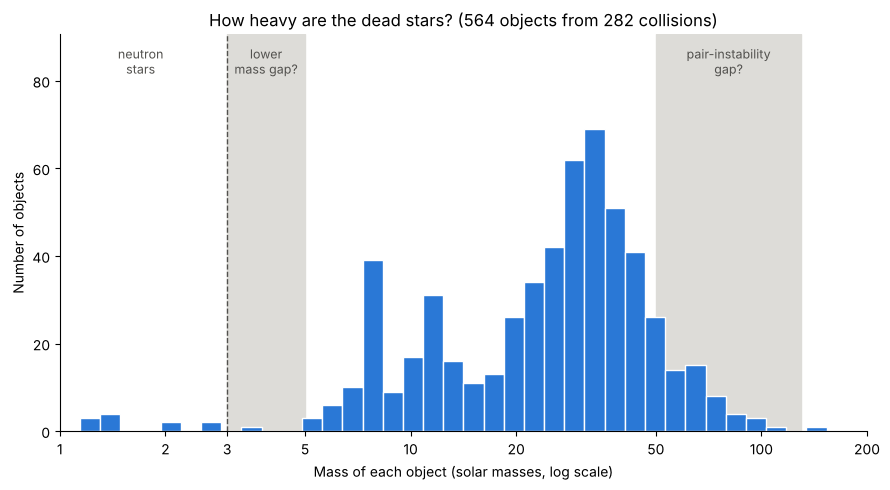

In [4]:
with_masses = events[events['type'] != 'No masses published yet']
masses = pd.concat([with_masses['mass_1_source'], with_masses['mass_2_source']])
print(len(masses), 'objects from', len(with_masses), 'collisions')

bins = np.logspace(0, np.log10(200), 41)   # 40 bars from 1 to 200 solar masses, evenly spaced on a log scale
fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(3, 5, color=GREY, zorder=0)       # lower mass gap
ax.axvspan(50, 130, color=GREY, zorder=0)    # pair-instability gap
ax.hist(masses, bins=bins, color=BLUE, edgecolor='white', linewidth=1, zorder=2)
ax.axvline(NS_LIMIT, color=INK, linestyle='--', linewidth=1, zorder=3)

ax.set_xscale('log')
ax.set_xlim(1, 200)
ticks = [1, 2, 3, 5, 10, 20, 50, 100, 200]
ax.set_xticks(ticks, labels=[str(t) for t in ticks])
ax.minorticks_off()
ymax = ax.get_ylim()[1] * 1.25               # leave room at the top for the labels
ax.set_ylim(0, ymax)
for x, label in [(1.7, 'neutron\nstars'), (np.sqrt(3 * 5), 'lower\nmass gap?'), (np.sqrt(50 * 130), 'pair-instability\ngap?')]:
    ax.text(x, ymax * 0.97, label, ha='center', va='top', color=INK, fontsize=9)

ax.set(xlabel='Mass of each object (solar masses, log scale)', ylabel='Number of objects',
       title=f'How heavy are the dead stars? ({len(masses)} objects from {len(with_masses)} collisions)')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(PLOTS / 'gw_mass_histogram.png', dpi=150)
plt.show()

**What this shows:** Most of the 564 objects are black holes between about 5 and 50 solar masses, with two bumps: a smaller one around 8-10 and a bigger one around 30-35 solar masses. Only 11 objects are lighter than 3 solar masses (probably neutron stars). Neutron stars are light, so their collisions are faint and the detectors only hear the nearby ones. The small number therefore partly reflects what the detectors can hear, not just how common neutron stars are.

**Are there masses nature seems to avoid?**
- **Lower mass gap (3-5 M☉): almost empty.** Only 1 of the 564 objects lands there (3.7 M☉, in the collision GW230529). That fits the idea of a real gap, and the one object inside it is interesting in itself.
- **Pair-instability gap (50-130 M☉): not empty.** 60 objects (from 53 collisions) have best-estimate masses in this range. The numbers fall off, but they don't drop to zero. Scientists are still debating why. These black holes might have formed in earlier collisions (a black hole that already merged once), the gap might start at a higher mass than predicted, or some mass estimates might be off (they have large uncertainties).

## 2. How the catalogue grew

This line counts every detection so far, in the order the collisions were detected. It includes all events, even those without published masses yet.

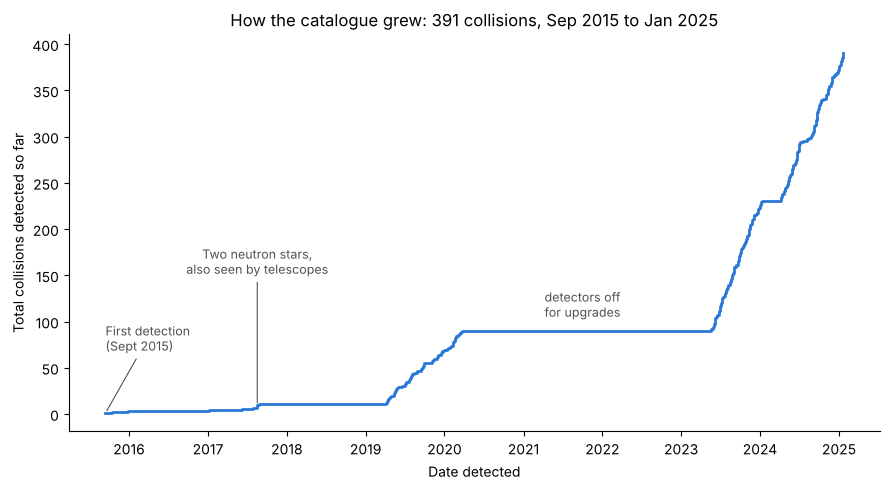

date
2015      3
2017      8
2019     58
2020     21
2023    136
2024    149
2025     16
Name: detections that year, dtype: int64

In [5]:
growth = events.sort_values('date').reset_index(drop=True)
growth['total so far'] = np.arange(1, len(growth) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.step(growth['date'], growth['total so far'], where='post', color=BLUE, linewidth=2)

# Label two famous detections
for name, label, height, align in [('GW150914', 'First detection\n(Sept 2015)', 45, 'left'),
                                   ('GW170817', 'Two neutron stars,\nalso seen by telescopes', 95, 'center')]:
    row = growth[growth['commonName'] == name].iloc[0]
    ax.annotate(label, xy=(row['date'], row['total so far']), xytext=(0, height), textcoords='offset points',
                ha=align, color=INK, fontsize=9, arrowprops=dict(arrowstyle='-', color=INK, linewidth=0.8))

# Label the long pause while the detectors were switched off for upgrades (2020-2023)
pause_level = growth.loc[growth['date'] < '2023-01-01', 'total so far'].max()
ax.text(pd.Timestamp('2021-10-01'), pause_level + 12, 'detectors off\nfor upgrades', ha='center', va='bottom',
        color=INK, fontsize=9)

ax.set(xlabel='Date detected', ylabel='Total collisions detected so far',
       title=f'How the catalogue grew: {len(growth)} collisions, {growth["date"].min():%b %Y} to {growth["date"].max():%b %Y}')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(PLOTS / 'gw_catalog_growth.png', dpi=150)
plt.show()

# Detections per year, for reference
events['date'].dt.year.value_counts().sort_index().rename('detections that year')

**What this shows:** The catalogue grew in bursts. Each steep stretch is an **observing run**, when the detectors were switched on and listening. Each flat stretch is a pause while they were being upgraded. After each upgrade the detectors were more sensitive, so they could hear collisions from farther away, and the amount of space within listening range grows very quickly with distance. That's why the detection rate jumped: 3 in 2015, 8 in 2017, 79 in 2019-2020, and about 300 between May 2023 and January 2025.

The newest detections in this file are from January 2025. Each observing run takes many months to analyse before its catalogue is published, so anything detected after January 2025 isn't in this file yet.

## 3. Final mass vs. distance

When two objects merge they become one, slightly lighter than the two added together. Here each dot is that final object. The faint lines through each dot are **error bars**: the range the true value probably lies in.

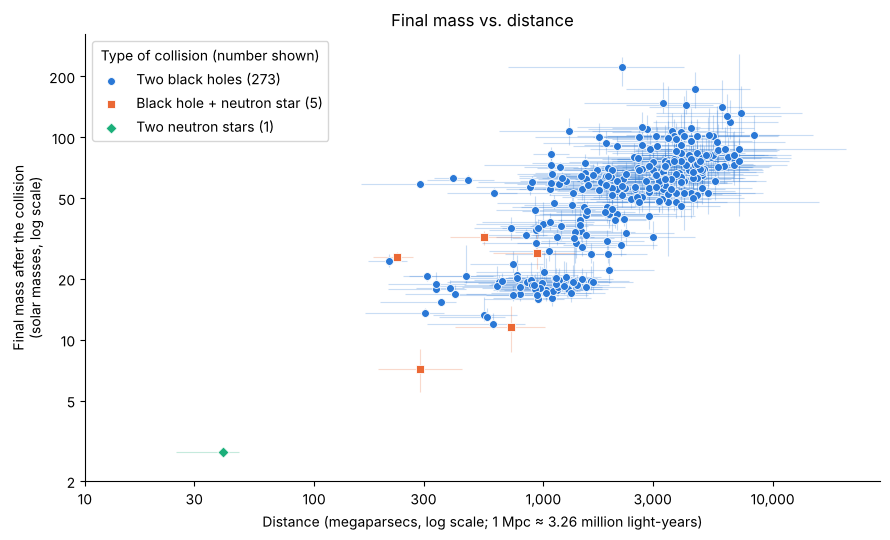

In [6]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for kind, (color, marker) in TYPE_STYLE.items():
    group = events[(events['type'] == kind) & events['final_mass_source'].notna()].fillna(0)
    # Error bars. The _lower and _upper columns are distances from the best value (lower ones are negative).
    # .to_numpy() turns each column into a plain list of numbers for matplotlib.
    ax.errorbar(group['luminosity_distance'].to_numpy(), group['final_mass_source'].to_numpy(),
                xerr=[-group['luminosity_distance_lower'].to_numpy(), group['luminosity_distance_upper'].to_numpy()],
                yerr=[-group['final_mass_source_lower'].to_numpy(), group['final_mass_source_upper'].to_numpy()],
                fmt='none', ecolor=color, alpha=0.25, linewidth=0.8, zorder=1)
    ax.scatter(group['luminosity_distance'], group['final_mass_source'], color=color, marker=marker, s=32,
               edgecolor='white', linewidth=0.6, zorder=2, label=f'{kind} ({len(group)})')

ax.set(xscale='log', yscale='log')
ax.set_xticks([10, 30, 100, 300, 1000, 3000, 10000], labels=['10', '30', '100', '300', '1,000', '3,000', '10,000'])
ax.set_yticks([2, 5, 10, 20, 50, 100, 200], labels=['2', '5', '10', '20', '50', '100', '200'])
ax.minorticks_off()
ax.set(xlabel='Distance (megaparsecs, log scale; 1 Mpc ≈ 3.26 million light-years)',
       ylabel='Final mass after the collision\n(solar masses, log scale)',
       title='Final mass vs. distance')
ax.legend(title='Type of collision (number shown)', loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(PLOTS / 'gw_final_mass_vs_distance.png', dpi=150)
plt.show()

**What this shows:** The final object is typically about 4% lighter than the two partners added together. That missing mass was turned into the energy of the gravitational waves.

The pattern to point out: **the farther away, the heavier.** The bottom-right corner is empty because light collisions far away are too faint for the detectors to hear. Heavy collisions are louder, so we can hear them from much farther away. This is called a **selection effect**: it tells us about what the detectors can hear, not that heavy black holes prefer to be far away. The two-neutron-star collision GW170817 (green diamond) is the lightest and by far the closest, at about 40 Mpc (130 million light-years). The farthest collisions are billions of light-years away.

The horizontal error bars are long. Distance is the hardest thing to measure here, often uncertain by around 50% either way. Only collisions with a published final mass are shown: 279 of the 282 with masses (the other 3 are 2 black hole + neutron star collisions and 1 two-neutron-star collision).

## Things to keep in mind

- Every mass and distance is a **best estimate** with an uncertainty (the error bars in plot 3). The histogram uses only the best estimates.
- The **3-solar-mass line** is a rough rule of thumb. An object near it, like the 2.6 M☉ partner in GW190814, could be a very heavy neutron star or a very light black hole. Nobody knows yet.
- **109 of the 391 collisions** (from GWTC-4.1 and GWTC-5.0) have no masses in this file yet, so they only appear in plot 2.
- The detectors pick up **loud (heavy or nearby) collisions** most easily, so these counts don't directly tell us how common each type is in the universe.

## Next steps (stretch goal)

- Colour the dots by **spin** (`chi_eff` column: how much the black holes were spinning in the same direction as their orbit).
- Look more closely at the objects inside the **pair-instability gap**, including their error bars. Are any clearly inside it?

## Data source and acknowledgement

Data: LIGO-Virgo-KAGRA Gravitational-Wave Transient Catalog (GWTC-1 to GWTC-5.0), downloaded from the Gravitational Wave Open Science Center event API, https://gwosc.org/eventapi/csv/GWTC/

GWOSC asks users to include this acknowledgement (first sentence shown; full text at https://gwosc.org/acknowledgement/):

> This research has made use of data or software obtained from the Gravitational Wave Open Science Center (gwosc.org), a service of the LIGO Scientific Collaboration, the Virgo Collaboration, and KAGRA.